# Regressão linear: um modelo de machine learning supera a régua?

## Por que este notebook existe

A LH Nautical decide **compra e estoque** com base em quanto cada produto deve vender nos **próximos 3 meses**, em cada loja. O notebook 04 montou uma regra simples que já faz essa previsão bem, a **régua**: média de venda da categoria na loja × sazonalidade × tendência de crescimento.

Aqui testamos se o modelo de machine learning mais simples, a **regressão linear**, prevê melhor. Só vale trocar a régua por um modelo se ele **superar a régua**.

## Resposta curta

**Não supera.** Nos mesmos 12 meses de teste do notebook 04 (o erro é o **WAPE**: de cada 100 unidades vendidas, quantas a previsão errou):

- **Por produto × loja, empata**: erro de 85,8% contra 86,6% da régua. Essa medida é dominada pelo acaso da venda de cada produto e diz pouco.
- **Depois de somar os produtos, perde**: 12,6% contra 11,9% por categoria no local, e 8,5% contra 6,1% por local. Para planejar compra por categoria ou por loja, a régua é mais confiável.
- **Erra sempre para baixo**: viés de −7,7% contra −2,8% da régua.
- **Ganha da régua em só 4 dos 12 meses.**
- **O que ele aprendeu bem foi a sazonalidade** (erro de 12,6% contra 36,4% da média móvel de 12 meses), mas isso a régua já fazia.

Os números acima são do modelo com todas as features (Linear 4), que é o **melhor dos quatro** modelos lineares no teste; os quatro estão no quadro da seção 6 e nenhum supera a régua. Como o Linear 4 foi apontado olhando o teste, a escolha só o favorece: o veredito não muda. As medidas são explicadas na seção 4 e os termos técnicos, no apêndice.

## 1. Como a regressão linear funciona

Pense em estimar o preço de um apartamento: um valor base, mais um tanto por metro quadrado, mais outro tanto por quarto. A regressão linear faz o mesmo, e quem descobre os "tantos" é o computador, olhando milhares de casos com a resposta conhecida.

Aqui, em vez do preço, prevemos **a venda dos próximos 3 meses** de cada produto × loja. As **pistas** (*features*) são coisas como: quanto a categoria vende naquela loja, se a época é de alta ou baixa temporada e se as vendas estão crescendo.

**Uma limitação que explica os resultados:** a regressão linear só **soma** (peso × pista). A régua **multiplica** (média × sazonalidade × tendência). Por isso um dos modelos abaixo recebe a multiplicação já pronta como pista.

Cada modelo acrescenta um grupo de features ao anterior:

| Modelo | O que recebe | Por que entra |
|---|---|---|
| **Linear 1** | Média de venda da categoria na loja, sazonalidade dos próximos 3 meses e tendência de crescimento | Os três ingredientes da régua |
| **Linear 2** | + a própria régua, já multiplicada | Entrega pronta a multiplicação que a regressão não sabe fazer |
| **Linear 3** | + vendas dos últimos 12 e dos últimos 3 meses do produto, em quantos meses ele vendeu no último ano e há quantos meses não vende | Histórico da própria série. O notebook 04 (seção 8) mostrou que ele quase não informa o futuro do produto; deixamos o modelo confirmar |
| **Linear 4** | + média do mesmo produto nos outros locais, em quantos locais ele é vendido e quantas séries a categoria tem no local | O mesmo produto nos outros locais e o tamanho do grupo |

Ficam de fora identificadores (SKU, nome), textos (categoria, marca, loja) e colunas que apenas repetem outras. Os nomes das colunas de cada modelo e o motivo de cada uma estão no apêndice (D).

## 2. Dados e divisão entre treino e teste

Cada linha da tabela de features é um **produto numa loja em um mês de corte** (o "hoje" da previsão). As colunas dizem o que se sabia **até aquele mês**, e o **alvo** é o que foi vendido **nos 3 meses seguintes**.

A divisão é **pelo tempo**, nunca sorteando linhas: sortear deixaria o modelo "espiar" meses vizinhos do teste.

```
passado ─────[ treino ]──(3 meses de folga)──[ teste: 12 cortes ]────► hoje
```

- **Teste:** os mesmos 12 cortes do notebook 04 (jun/25 a mai/26), para a comparação com a régua ser justa.
- **Treino:** todos os cortes anteriores, com 3 meses de folga: o alvo da última linha de treino (3 meses à frente) precisa ter terminado antes de o teste começar.

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics_ai.demand_common import add_months, cutoff_wape, scorecard_vs_ruler
from src.analytics_ai.demand_linear import (
    ESSENTIAL_FEATURES,
    GROUP_FEATURES,
    HISTORY_FEATURES,
    RULER_FEATURE,
    fit_linear,
    load_linear_panel,
    predict_nonnegative,
)
from src.analytics_ai.demand_plots import COLORS as CORES
from src.analytics_ai.demand_plots import comparison_chart
from src.analytics_ai.ml_config import MlFeatureConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100

config = MlFeatureConfig.from_environment_monthly()
TABELA_FEATURES = f"{config.catalog}.{config.schema}.ml_features_produto_loja_mes"

In [2]:
ESSENCIAIS = ESSENTIAL_FEATURES
REGUA = RULER_FEATURE
HISTORICO = HISTORY_FEATURES
GRUPO_EXTRA = GROUP_FEATURES

# Uma única leitura do Databricks: só linhas com alvo conhecido e tendência pronta
# (os primeiros cortes não têm 24 meses de histórico).
dados, descartadas = load_linear_panel(spark, TABELA_FEATURES)

print(f"linhas lidas: {len(dados) + descartadas:,} | descartadas por valor ausente: {descartadas:,}")
print(f"cortes: {dados['cutoff'].min()} a {dados['cutoff'].max()} ({dados['cutoff'].nunique()} cortes)")

linhas lidas: 322,578 | descartadas por valor ausente: 1,658
cortes: 2021-12-01 a 2026-05-01 (54 cortes)


In [3]:
cortes = sorted(dados["cutoff"].unique())
CORTES_TESTE = cortes[-12:]
ULTIMO_CORTE_TREINO = add_months(CORTES_TESTE[0], -3)  # o alvo do treino termina antes do teste

treino = dados[dados["cutoff"] <= ULTIMO_CORTE_TREINO].copy()
teste = dados[dados["cutoff"].isin(CORTES_TESTE)].copy()

print(f"treino: {len(treino):,} linhas | cortes {str(treino['cutoff'].min())[:7]} a {str(treino['cutoff'].max())[:7]}")
print(f"teste:  {len(teste):,} linhas | cortes {str(teste['cutoff'].min())[:7]} a {str(teste['cutoff'].max())[:7]}")
print(f"séries por corte no teste: {len(teste) / len(CORTES_TESTE):,.0f} (notebook 04: 6.054)")

# Referências do notebook 04, recalculadas a partir das colunas da tabela de features.
teste["pred_mm3"] = teste["sum_3m"]
teste["pred_mm12"] = teste["sum_12m"] / 12 * 3
teste["pred_mm12_idx"] = teste["sum_12m"] / 12 * teste["season_sum_next_3m"]

treino: 236,164 linhas | cortes 2021-12 a 2025-03
teste:  72,648 linhas | cortes 2025-06 a 2026-05
séries por corte no teste: 6,054 (notebook 04: 6.054)


**O que o resultado mostra:** o teste tem o mesmo desenho do notebook 04 (12 cortes e 6.054 séries por corte). Qualquer diferença de erro vem do **método de previsão**, não de um teste mais fácil ou mais difícil.

## 3. Treinar os quatro modelos

Uma venda nunca é negativa, mas uma soma de pesos pode dar menos que zero: previsões negativas viram zero. A tabela mostra o que o modelo mais simples (Linear 1) aprendeu: quanto a previsão muda quando cada pista sobe **1 desvio-padrão** (uma medida que permite comparar pistas de escalas muito diferentes).

In [4]:
CANDIDATOS = {
    "Linear 1: essenciais": ESSENCIAIS,
    "Linear 2: + régua pronta": [*ESSENCIAIS, REGUA],
    "Linear 3: + histórico da série": [*ESSENCIAIS, REGUA, *HISTORICO],
    "Linear 4: + produto nos outros locais": [*ESSENCIAIS, REGUA, *HISTORICO, *GRUPO_EXTRA],
}

modelos = {}
for i, (nome, colunas) in enumerate(CANDIDATOS.items(), start=1):
    modelos[nome] = fit_linear(treino, colunas)
    # Venda nunca é negativa: previsões abaixo de zero viram zero.
    teste[f"pred_linear_{i}"] = predict_nonnegative(modelos[nome], teste, colunas)

# O que o modelo mais simples aprendeu: quanto a previsão muda com +1 desvio-padrão de cada pista.
m1 = modelos["Linear 1: essenciais"]
pesos = pd.DataFrame(
    {
        "peso": m1.coef_,
        "efeito de +1 desvio-padrão (unidades em 3 meses)": m1.coef_ * treino[ESSENCIAIS].std().to_numpy(),
    },
    index=["nível da categoria na loja", "sazonalidade dos próximos 3 meses", "tendência de crescimento"],
).round(3)
display(pesos)

,peso,efeito de +1 desvio-padrão (unidades em 3 meses)
nível da categoria na loja,0.175,0.409
sazonalidade dos próximos 3 meses,1.610,1.645
tendência de crescimento,0.341,0.028


**O que o resultado mostra:** a **sazonalidade** é a pista que mais pesa. Subir 1 desvio-padrão na sazonalidade dos próximos 3 meses muda a previsão em cerca de 1,6 unidade, contra 0,4 para o nível da categoria na loja e 0,03 para a tendência. Faz sentido: entre um trimestre de alta e um de baixa temporada, a venda muda muito.

## 4. Como medimos

Usamos a **mesma função de medição** do notebook 04, na mesma tabela de teste:

| Medida | Em palavras simples | Melhor |
|---|---|---|
| Erro por produto × loja (WAPE) | De cada 100 unidades vendidas, quantas a previsão errou, produto a produto | Menor (mas premia prever abaixo do real) |
| Erro por categoria no local e por local (WAPE) | O mesmo erro, **depois de somar** os produtos. É o que importa para decidir compra por categoria ou por loja | Menor |
| Viés | Se a previsão erra sempre para o mesmo lado. −10% = a previsão fica 10% abaixo do vendido | Perto de zero |
| MAE e RMSE | Erro médio em **unidades** por produto × loja. O RMSE pesa mais os erros grandes | Menor |
| Cortes ganhos da régua | Em quantos dos 12 meses o método erra menos que a régua por categoria no local | Mais |

**Regra do notebook 04:** um método só é "melhor" se ganhar **na maioria dos 12 cortes**, e não só na média.

## 5. Mês a mês: onde o Linear 4 perde para a régua

Uma média pode esconder meses em que o modelo vai mal. O gráfico compara a régua com o Linear 4 (o modelo com todas as features, o melhor dos quatro no teste) em cada mês de corte.

Linear 4 ganha da régua em 4 de 12 cortes: ['2025-09', '2025-10', '2025-11', '2026-03']


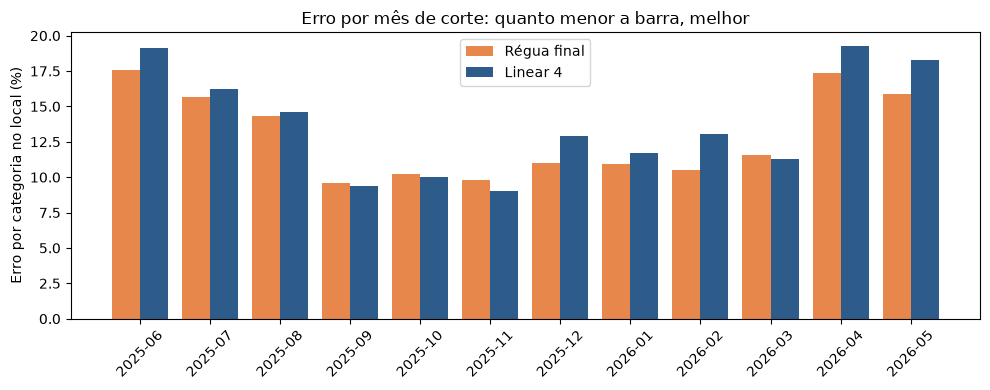

,Régua final,Linear 4
cutoff,,
2025-06-01,17.6,19.1
2025-07-01,15.7,16.2
2025-08-01,14.3,14.6
2025-09-01,9.6,9.4
2025-10-01,10.2,10.0
2025-11-01,9.8,9.0
2025-12-01,11.0,12.9
2026-01-01,10.9,11.7
2026-02-01,10.5,13.1


In [5]:
# Linear 4 = o modelo com todas as features.
por_corte = pd.DataFrame({"Régua final": cutoff_wape(teste, REGUA), "Linear 4": cutoff_wape(teste, "pred_linear_4")})
ganha = por_corte["Linear 4"] < por_corte["Régua final"]
print(f"Linear 4 ganha da régua em {int(ganha.sum())} de {len(por_corte)} cortes: {[str(c)[:7] for c in ganha[ganha].index]}")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(por_corte))
ax.bar(x - 0.2, por_corte["Régua final"] * 100, 0.4, color=CORES[1], label="Régua final")
ax.bar(x + 0.2, por_corte["Linear 4"] * 100, 0.4, color=CORES[0], label="Linear 4")
ax.set_xticks(x)
ax.set_xticklabels([str(c)[:7] for c in por_corte.index], rotation=45)
ax.set_ylabel("Erro por categoria no local (%)")
ax.set_title("Erro por mês de corte: quanto menor a barra, melhor")
ax.legend()
plt.tight_layout()
plt.show()
# Mesmos valores do gráfico, em tabela (erro por categoria no local, %).
display((por_corte * 100).round(1))


**O que o resultado mostra:** o Linear 4 ganha da régua em **4 de 12 meses** (set, out e nov/25 e mar/26) e perde nos outros 8 (jun a ago/25, dez/25 a fev/26 e abr a mai/26). Em fev/26, por exemplo, o erro é de 13,1% contra 10,5%. Pela regra do notebook 04 (ganhar na **maioria** dos cortes), ele não passa.

**Uma hipótese:** a régua recalcula sazonalidade e tendência a cada corte, enquanto a regressão linear aprende **um único conjunto de pesos** para todo o treino (2021 a 2025). Se o crescimento mudou muito nesse período, os pesos ficam ajustados a um passado que não é o do teste. A célula abaixo mede o **fator de tendência** de cada corte (quanto as vendas dos últimos 12 meses cresceram sobre os 12 anteriores, ajustado ao horizonte da previsão).

Uma ressalva: essa hipótese nasceu de olhar os resultados do teste. Quem a testa de verdade, com uma validação separada, é o notebook 05b.

In [6]:
# O fator de tendência é o mesmo para todas as séries de um corte.
assert dados.groupby("cutoff")["trend_factor"].nunique().max() == 1
tendencia = dados.groupby("cutoff")["trend_factor"].first()
no_treino = tendencia[tendencia.index.isin(treino["cutoff"].unique())]
no_teste = tendencia[tendencia.index.isin(CORTES_TESTE)]

resumo = pd.DataFrame(
    {
        "treino": [no_treino.iloc[0], no_treino.iloc[-1], no_treino.mean(), no_treino.min(), no_treino.max()],
        "teste": [no_teste.iloc[0], no_teste.iloc[-1], no_teste.mean(), no_teste.min(), no_teste.max()],
    },
    index=["primeiro corte", "último corte", "média", "menor", "maior"],
).round(2)
display(resumo)

,treino,teste
primeiro corte,1.53,1.08
último corte,1.09,1.10
média,1.14,1.10
menor,1.08,1.08
maior,1.53,1.11


**O que o resultado mostra:** o fator de tendência era **1,53** no primeiro corte do treino (dez/21) e **1,09** no último (mar/25); nos 12 cortes de teste fica entre **1,08 e 1,11**. A média do treino (1,14) é próxima à do teste (1,10). O crescimento mudou de regime, mas o que destoa são os **primeiros cortes do treino**; os mais recentes já se parecem com o teste.

Então a hipótese explica pouco por si só: um único conjunto de pesos aprendido em 2021 a 2025 não está tão distante do teste quanto parecia. Isso combina com o que o notebook 05b encontra: encurtar a janela de treino ajudou na validação e não se sustentou no teste.

## 6. Comparação final com a régua e as médias móveis

O quadro abaixo segue o formato da seção 14 do notebook 04 (a "nota a superar") e acrescenta os quatro modelos lineares e, na última coluna, em quantos dos 12 meses cada um ganha da régua.

,Erro por produto × loja (%),Erro por categoria no local (%),Erro por local (%),Viés (%),MAE (unidades),RMSE (unidades),Cortes ganhos da régua (de 12)
previsao,,,,,,,
MM3,120.47,49.58,48.72,-1.93,6.93,9.46,0
MM12,99.23,36.35,35.50,-8.08,5.71,7.40,0
MM12 × índice,93.10,15.07,12.03,-11.68,5.36,7.13,0
Régua final,86.57,11.91,6.09,-2.75,4.98,6.38,–
Linear 1: essenciais,86.41,13.79,10.26,-7.84,4.97,6.40,2
Linear 2: + régua pronta,85.77,12.79,8.75,-7.92,4.93,6.39,3
Linear 3: + histórico da série,85.73,12.86,8.83,-8.14,4.93,6.39,3
Linear 4: + produto nos outros locais,85.79,12.63,8.46,-7.70,4.94,6.39,4


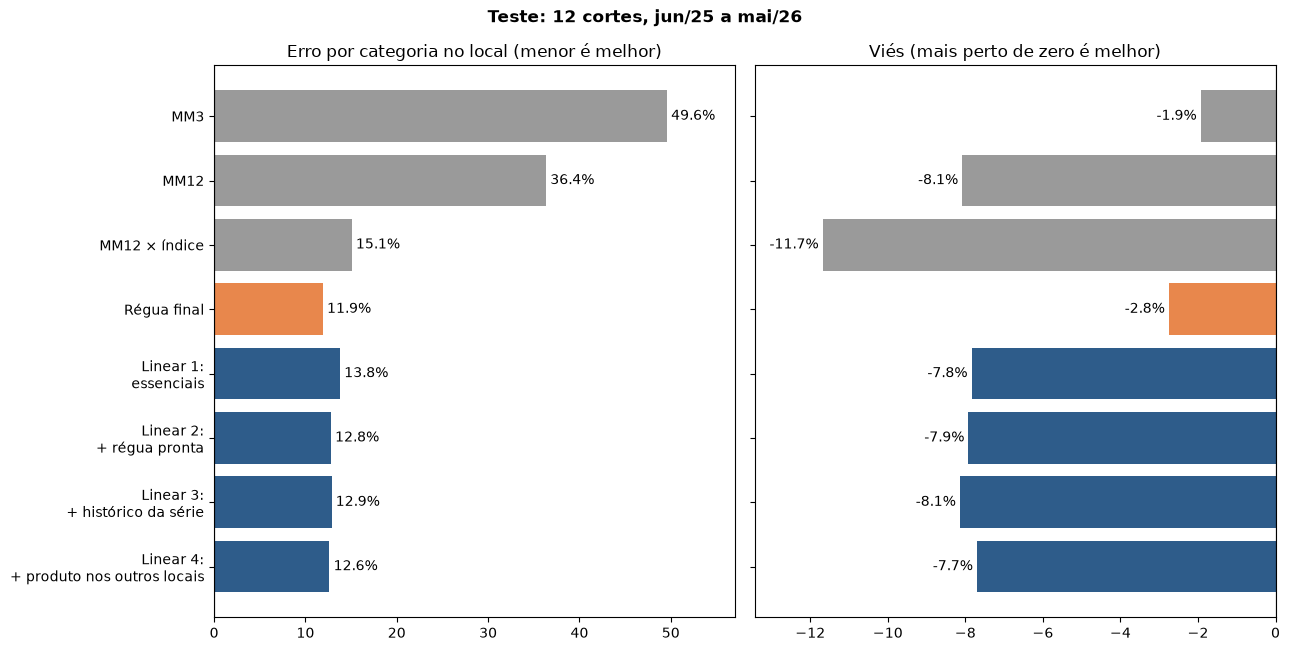

In [7]:
METODOS = {
    "MM3": "pred_mm3",
    "MM12": "pred_mm12",
    "MM12 × índice": "pred_mm12_idx",
    "Régua final": REGUA,
    **{nome: f"pred_linear_{i}" for i, nome in enumerate(CANDIDATOS, start=1)},
}

quadro = scorecard_vs_ruler(teste, METODOS, ruler_col=REGUA)
display(quadro)
comparison_chart(quadro, "Teste: 12 cortes, jun/25 a mai/26")
plt.show()

**O que o quadro mostra:**

- **Contra as médias móveis, o modelo é bem melhor no erro somado:** 12,6% contra 36,4% da MM12 e 15,1% da MM12 × índice. Ele aprendeu a sazonalidade. Mas o viés (−7,7%) é quase o da MM12 (−8,1%): não corrigiu o efeito do crescimento.
- **Contra a régua, perde nas medidas que importam para a decisão:** 12,6% contra 11,9% por categoria no local, 8,5% contra 6,1% por local, e viés de −7,7% contra −2,8%.
- **Por produto × loja, tudo empata:** erro de 85,7% a 86,4% nos quatro lineares contra 86,6% da régua; MAE e RMSE quase idênticos (RMSE de 6,38 a 6,40). Por produto, nenhum método se separa dos outros.
- **Linear 2 (régua pronta) ajuda:** o erro por categoria no local cai de 13,8% para 12,8% e o erro por local, de 10,3% para 8,8%. Entregar a multiplicação pronta ajuda um modelo que só sabe somar.
- **Linear 3 (histórico da série) não ajuda:** 12,9% por categoria no local e viés de −8,1%. Confirma o notebook 04: o histórico de um produto não informa o futuro dele.
- **Linear 4 melhora apenas décimos** (12,6%). Não vale ler mais que isso.
- **Viés perto de zero não basta:** a MM3 tem viés de −1,9%, mas erra 49,6% por categoria no local.

## Conclusão

**Veredito: a regressão linear não supera a régua.** A régua do notebook 04 continua sendo a nota a superar.

- Empata por produto, perde depois de somar (por categoria e por local) e tem mais viés.
- Ganha da régua em 4 de 12 meses, abaixo da maioria exigida.
- O Linear 4 é o melhor dos quatro no teste e foi apontado olhando o teste; isso só o favorece, e mesmo assim ele não passa.
- A sazonalidade é a pista que mais pesa; entregar a régua pronta como feature ajuda; o histórico da própria série não ajuda.
- Empatar por produto não basta: o que separa os métodos é o erro somado e o viés.

**Para a LH Nautical:** seguir usando a régua para planejar compra e estoque. A regressão linear não traz ganho que justifique a troca.

**Próximo passo:** o notebook 05b escolhe features, janela de treino e regularização numa **validação separada** (sem olhar o teste) para ver se um modelo linear bem ajustado consegue superar a régua. Modelos não lineares e de contagem (Poisson) devem ser medidos neste mesmo teste e neste mesmo quadro.

---

## Apêndice

### A. Como a regressão linear aprende

A previsão é uma soma de pistas multiplicadas por pesos, mais um valor base:

$$
\hat y = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_k x_k
$$

- $\hat y$ = previsão (o total dos 3 meses seguintes)
- $x_1, \dots, x_k$ = as features (as pistas)
- $b_1, \dots, b_k$ = os **pesos** (coeficientes), aprendidos no treino
- $b_0$ = o **intercepto** (valor base)

O computador testa combinações de pesos e fica com a que deixa o **erro quadrático médio** do treino mais baixo:

$$
\text{erro do treino} = \frac{1}{n}\sum_i (\hat y_i - y_i)^2
$$

Elevar ao quadrado faz os erros grandes pesarem muito mais que os pequenos (é também o motivo de o RMSE importar aqui).

### B. Fórmulas das medidas

$$
\text{WAPE} = \frac{\sum_i |\hat y_i - y_i|}{\sum_i y_i}
\qquad
\text{viés} = \frac{\sum_i \hat y_i - \sum_i y_i}{\sum_i y_i}
\qquad
\text{MAE} = \frac{1}{n}\sum_i |\hat y_i - y_i|
\qquad
\text{RMSE} = \sqrt{\frac{1}{n}\sum_i (\hat y_i - y_i)^2}
$$

- $y_i$ = vendido e $\hat y_i$ = previsto na série $i$ (um produto × loja em um corte)
- **MM12 / MM3** = venda média mensal dos últimos 12 / 3 meses, × 3. **MM12 × índice** troca o "× 3" pela soma dos índices sazonais dos 3 meses previstos.

### C. Glossário

| Termo | O que quer dizer, em palavras simples |
|---|---|
| Feature | Uma coluna que o modelo usa como **pista** para prever |
| Alvo (`target_3m`) | O que queremos prever: o total vendido nos 3 meses seguintes ao corte |
| Modelo | A "fórmula" que transforma as pistas em uma previsão. É **aprendida** dos dados, não escrita à mão |
| Treino | Os dados que o modelo vê para aprender. Aqui, ele vê as features **e** o alvo |
| Teste | Dados que o modelo **nunca viu**, usados só para dar a nota final. É a "prova" |
| Peso (coeficiente) | Quanto a previsão muda quando uma feature sobe 1 unidade |
| Intercepto | O valor base da previsão, quando todas as features valem zero |
| Corte | O "hoje" de cada linha: só entra informação disponível até esse mês |
| Vazamento (*leakage*) | Deixar o modelo enxergar o futuro no treino. A nota parece ótima e a previsão real falha |
| Índice sazonal / tendência | Quanto um mês vende acima ou abaixo da média do ano / o empurrão que compensa o crescimento (notebook 04) |

### D. Limitações

- **Só soma.** Não captura relações como "a sazonalidade pesa mais nas categorias grandes" sem que alguém crie essa coluna. É por isso que a régua pronta ajuda tanto.
- **Não entende contagem.** Previsão negativa é corrigida cortando em zero, mas o modelo não sabe que o alvo é uma contagem com muitos zeros.
- **Nenhum modelo é escolhido aqui.** Os quatro são medidos no mesmo teste e o Linear 4 é apenas o de todas as features. Escolher ajustes olhando o teste tiraria dele o papel de prova limpa; é o que o notebook 05b resolve com uma validação.

### D. Nomes das colunas de cada modelo

O motivo de cada coluna está em `docs/dicionario_features_ml_produto_loja_mes.md`.

| Em palavras simples | Coluna | Entra a partir do |
|---|---|---|
| Média de venda da categoria na loja | `categoria_local_avg_12m` | Linear 1 |
| Sazonalidade dos próximos 3 meses | `season_sum_next_3m` | Linear 1 |
| Tendência de crescimento | `trend_factor` | Linear 1 |
| A régua já multiplicada | `baseline_pred_categoria_local_idx_trend` | Linear 2 |
| Vendas dos últimos 12 meses do produto | `sum_12m` | Linear 3 |
| Vendas dos últimos 3 meses do produto | `sum_3m` | Linear 3 |
| Meses com venda no último ano | `months_with_sale_12m` | Linear 3 |
| Meses desde a última venda | `months_since_last_sale` | Linear 3 |
| Média do produto nos outros locais | `produto_locais_avg_12m` | Linear 4 |
| Em quantos locais o produto é vendido | `produto_locais_n_locations` | Linear 4 |
| Quantas séries a categoria tem no local | `categoria_local_n_series` | Linear 4 |
